# Financial Data Extraction and Analysis: Microsoft, Tesla and Apple (FY2023 to FY2025)
**BCG GenAI Job Simulation (Forage), Task 1**
**Prepared by:** Gibson Nyendwa, Junior Data Scientist, GenAI Consulting Team
**For:** Aisha, Senior Data Scientist | **Client:** Global Finance Corp. (GFC)

---

## Objective
GFC wants an AI-powered chatbot that analyses corporate financial performance from 10-K and 10-Q filings and explains it in plain language. This notebook lays the foundation: it extracts key figures from the 10-K filings of **Microsoft, Tesla and Apple for fiscal years 2023 to 2025**, analyses the trends with pandas, and prepares a clean dataset for the chatbot.

## Contents
1. Methodology
2. Load the data (Excel to CSV to DataFrame)
3. Data cleaning and quality checks
4. Year-on-year changes
5. Aggregates across companies and years
6. Financial health ratios
7. Three-year summary
8. Visualising the trends
9. AI-ready preprocessing
10. Findings and conclusions
11. Export for the chatbot

## 1. Methodology

**Data source.** Each company's Form 10-K annual report on the SEC's EDGAR database:
- Microsoft (CIK 789019), Tesla (CIK 1318605), Apple (CIK 320193)

**Extraction.** Figures were extracted manually from **Item 8 (Financial Statements)** of each 10-K and compiled into an Excel spreadsheet (`data/financial_data.xlsx`). Explanations for unusual movements were taken from **Item 7 (Management's Discussion and Analysis)** and company results releases.

| Metric | Statement in Item 8 | Why it matters |
|---|---|---|
| Total Revenue | Income statement | Size and growth of the business |
| Net Income | Income statement | Bottom-line profitability |
| Total Assets | Balance sheet | Scale of resources owned |
| Total Liabilities | Balance sheet | Obligations and leverage |
| Cash Flow from Operating Activities | Cash flow statement | Whether profit turns into real cash |

**Conventions.**
- All values are in **US$ millions**, as reported.
- Fiscal years end on different dates: Microsoft on **30 June**, Apple in **late September**, Tesla on **31 December**. Comparisons are by each company's own fiscal year, not calendar year.
- Tesla's net income is *net income attributable to common stockholders*, the headline figure in its 10-K.

**Analysis.** pandas is used to calculate year-on-year changes, aggregate the data by company and by year, derive financial health ratios, and summarise each company's three-year performance.

## 2. Load the data
Following the task steps: the Excel spreadsheet of extracted figures is converted to CSV, then loaded into a pandas DataFrame.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)
DATA = Path("../data")
CHARTS = Path("../charts")
CHARTS.mkdir(exist_ok=True)

# Convert the Excel spreadsheet of extracted 10-K figures to CSV
pd.read_excel(DATA / "financial_data.xlsx", sheet_name="10-K Data", nrows=9).to_csv(
    DATA / "financial_data.csv", index=False)

# Load the CSV into a DataFrame
df = pd.read_csv(DATA / "financial_data.csv")
df = df.sort_values(["Company", "Fiscal Year"]).reset_index(drop=True)
df

,Company,Fiscal Year,Fiscal Year End,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Operating Activities
0,Apple,2023,2023-09-30,383285,96995,352583,290437,110543
1,Apple,2024,2024-09-28,391035,93736,364980,308030,118254
2,Apple,2025,2025-09-27,416161,112010,359241,285508,111482
3,Microsoft,2023,2023-06-30,211915,72361,411976,205753,87582
4,Microsoft,2024,2024-06-30,245122,88136,512163,243686,118548
5,Microsoft,2025,2025-06-30,281724,101832,619003,275524,136162
6,Tesla,2023,2023-12-31,96773,14997,106618,43009,13256
7,Tesla,2024,2024-12-31,97690,7091,122070,48390,14923
8,Tesla,2025,2025-12-31,94827,3794,137806,54941,14747


## 3. Data cleaning and quality checks
An AI model is only as reliable as the data it is fed, so the data is checked before any analysis:
- **Missing values:** none expected. Any gap would be traced back to the 10-K rather than filled with an estimate, because invented financial figures would undermine the chatbot's accuracy.
- **Duplicates:** each company and fiscal year must appear exactly once.
- **Consistent format:** every metric must be numeric and in the same unit (US$ millions).
- **Sense check:** liabilities should be below assets for these companies.

In [2]:
METRICS = ["Total Revenue", "Net Income", "Total Assets",
           "Total Liabilities", "Cash Flow from Operating Activities"]

print("Rows and columns:", df.shape)
print("Missing values:", int(df[METRICS].isna().sum().sum()))
print("Duplicate company-year rows:", int(df.duplicated(subset=["Company", "Fiscal Year"]).sum()))
print("Years per company:", df.groupby("Company")["Fiscal Year"].apply(list).to_dict())
print("All metrics numeric:", all(pd.api.types.is_numeric_dtype(df[m]) for m in METRICS))
print("Liabilities below assets in every row:", bool((df["Total Liabilities"] < df["Total Assets"]).all()))
df[METRICS].describe()

Rows and columns: (9, 8)
Missing values: 0
Duplicate company-year rows: 0
Years per company: {'Apple': [2023, 2024, 2025], 'Microsoft': [2023, 2024, 2025], 'Tesla': [2023, 2024, 2025]}
All metrics numeric: True
Liabilities below assets in every row: True


,Total Revenue,Net Income,Total Assets,Total Liabilities,Cash Flow from Operating Activities
count,9.00,9.00,9.00,9.00,9.00
mean,"246,503.56","65,661.33","331,826.67","195,030.89","80,610.78"
std,"131,525.38","44,160.82","178,905.59","113,610.10","51,270.53"
min,"94,827.00","3,794.00","106,618.00","43,009.00","13,256.00"
25%,"97,690.00","14,997.00","137,806.00","54,941.00","14,923.00"
50%,"245,122.00","88,136.00","359,241.00","243,686.00","110,543.00"
75%,"383,285.00","96,995.00","411,976.00","285,508.00","118,254.00"
max,"416,161.00","112,010.00","619,003.00","308,030.00","136,162.00"


All checks pass: the dataset is complete, unique, consistently formatted and financially sensible.

## 4. Year-on-year changes
`groupby('Company')` with `pct_change()` calculates each company's change against its own previous year, so companies are never compared with each other by mistake. Each company's first year (FY2023) has no prior year in the dataset, so it shows as blank (NaN).

In [3]:
df['Revenue Growth (%)'] = df.groupby(['Company'])['Total Revenue'].pct_change() * 100
df['Net Income Growth (%)'] = df.groupby(['Company'])['Net Income'].pct_change() * 100
df['Assets Growth (%)'] = df.groupby(['Company'])['Total Assets'].pct_change() * 100
df['Liabilities Growth (%)'] = df.groupby(['Company'])['Total Liabilities'].pct_change() * 100
df['Operating Cash Flow Growth (%)'] = df.groupby(['Company'])['Cash Flow from Operating Activities'].pct_change() * 100

GROWTH_COLS = ['Revenue Growth (%)', 'Net Income Growth (%)', 'Assets Growth (%)',
               'Liabilities Growth (%)', 'Operating Cash Flow Growth (%)']
df[['Company', 'Fiscal Year'] + GROWTH_COLS]

,Company,Fiscal Year,Revenue Growth (%),Net Income Growth (%),Assets Growth (%),Liabilities Growth (%),Operating Cash Flow Growth (%)
0,Apple,2023,NaN,NaN,NaN,NaN,NaN
1,Apple,2024,2.02,-3.36,3.52,6.06,6.98
2,Apple,2025,6.43,19.50,-1.57,-7.31,-5.73
3,Microsoft,2023,NaN,NaN,NaN,NaN,NaN
4,Microsoft,2024,15.67,21.80,24.32,18.44,35.36
5,Microsoft,2025,14.93,15.54,20.86,13.07,14.86
6,Tesla,2023,NaN,NaN,NaN,NaN,NaN
7,Tesla,2024,0.95,-52.72,14.49,12.51,12.58
8,Tesla,2025,-2.93,-46.50,12.89,13.54,-1.18


**Observations**
- **Microsoft** grew revenue by about 15% in both FY2024 and FY2025, with net income up 21.8% and 15.5%.
- **Apple** re-accelerated: revenue growth rose from 2.0% to 6.4%, and net income jumped 19.5% in FY2025 after a 3.4% dip in FY2024.
- **Tesla** is going the other way: revenue fell 2.9% in FY2025, its first annual decline in this period, and net income fell for a second year running (−52.7%, then −46.5%).

## 5. Aggregates across companies and years
Looking at the data along different dimensions: averages by company, totals by year, and pivot tables that put companies side by side.

In [4]:
print("Average annual growth by company, FY2024 to FY2025 (%)")
df.groupby('Company')[GROWTH_COLS].mean()

Average annual growth by company, FY2024 to FY2025 (%)


,Revenue Growth (%),Net Income Growth (%),Assets Growth (%),Liabilities Growth (%),Operating Cash Flow Growth (%)
Company,,,,,
Apple,4.22,8.07,0.97,-0.63,0.62
Microsoft,15.30,18.67,22.59,15.75,25.11
Tesla,-0.99,-49.61,13.69,13.02,5.70


In [5]:
print("Three-year totals by company (US$ millions)")
df.groupby('Company')[['Total Revenue', 'Net Income', 'Cash Flow from Operating Activities']].sum()

Three-year totals by company (US$ millions)


,Total Revenue,Net Income,Cash Flow from Operating Activities
Company,,,
Apple,1190481,302741,340279
Microsoft,738761,262329,342292
Tesla,289290,25882,42926


In [6]:
print("Combined totals across all three companies by fiscal year (US$ millions)")
by_year = df.groupby('Fiscal Year')[['Total Revenue', 'Net Income']].sum()
by_year['Combined Revenue Growth (%)'] = by_year['Total Revenue'].pct_change() * 100
by_year

Combined totals across all three companies by fiscal year (US$ millions)


,Total Revenue,Net Income,Combined Revenue Growth (%)
Fiscal Year,,,
2023,691973,184353,NaN
2024,733847,188963,6.05
2025,792712,217636,8.02


In [7]:
print("Net income by company and year (US$ millions)")
df.pivot(index='Fiscal Year', columns='Company', values='Net Income')

Net income by company and year (US$ millions)


Company,Apple,Microsoft,Tesla
Fiscal Year,,,
2023,96995,72361,14997
2024,93736,88136,7091
2025,112010,101832,3794


In [8]:
print("Share of the three companies' combined net income (%)")
ni = df.pivot(index='Fiscal Year', columns='Company', values='Net Income')
(ni.div(ni.sum(axis=1), axis=0) * 100).round(1)

Share of the three companies' combined net income (%)


Company,Apple,Microsoft,Tesla
Fiscal Year,,,
2023,52.60,39.30,8.10
2024,49.60,46.60,3.80
2025,51.50,46.80,1.70


**Observations**
- Apple earns the most revenue, about $1.19 trillion over three years, but Microsoft's revenue is growing far faster.
- Combined net income for the three companies rose every year. Tesla's share fell from 8.1% to 1.7% of the total, while Microsoft's rose from 39.3% to 46.8%.

## 6. Financial health ratios
Raw figures favour the biggest company. Ratios make companies of different sizes comparable:
- **Net margin (%)** = Net Income ÷ Total Revenue. Profit kept from each dollar of sales.
- **Liabilities to assets (%)** = Total Liabilities ÷ Total Assets. Leverage: the share of assets funded by liabilities.
- **Operating cash flow to net income (x)** = Operating Cash Flow ÷ Net Income. Earnings quality: above 1.0 means profit is backed by real cash.
- **Shareholders' equity** = Total Assets − Total Liabilities (the balance sheet identity).

In [9]:
df['Net Margin (%)'] = df['Net Income'] / df['Total Revenue'] * 100
df['Liabilities to Assets (%)'] = df['Total Liabilities'] / df['Total Assets'] * 100
df['OCF to Net Income (x)'] = df['Cash Flow from Operating Activities'] / df['Net Income']
df['Shareholders Equity'] = df['Total Assets'] - df['Total Liabilities']

RATIO_COLS = ['Net Margin (%)', 'Liabilities to Assets (%)', 'OCF to Net Income (x)', 'Shareholders Equity']
df[['Company', 'Fiscal Year'] + RATIO_COLS]

,Company,Fiscal Year,Net Margin (%),Liabilities to Assets (%),OCF to Net Income (x),Shareholders Equity
0,Apple,2023,25.31,82.37,1.14,62146
1,Apple,2024,23.97,84.40,1.26,56950
2,Apple,2025,26.92,79.48,1.00,73733
3,Microsoft,2023,34.15,49.94,1.21,206223
4,Microsoft,2024,35.96,47.58,1.35,268477
5,Microsoft,2025,36.15,44.51,1.34,343479
6,Tesla,2023,15.50,40.34,0.88,63609
7,Tesla,2024,7.26,39.64,2.10,73680
8,Tesla,2025,4.00,39.87,3.89,82865


**Observations**
- **Microsoft** has the highest margins (34 to 36%) and its leverage fell every year, to 44.5%.
- **Apple's** margin recovered to 26.9% in FY2025. Its leverage is high (about 80%) because it returns large amounts of cash to shareholders through buybacks and dividends, which keeps equity low. This is a deliberate choice, not a sign of distress.
- **Tesla's** margin shrank from 15.5% to 4.0%. However, operating cash flow was 3.9 times net income in FY2025, so the business still generates far more cash than its reported profit suggests.

## 7. Three-year summary
The compound annual growth rate (CAGR) over FY2023 to FY2025 gives one comparable growth figure per company.

In [10]:
def cagr(series):
    periods = len(series) - 1
    return ((series.iloc[-1] / series.iloc[0]) ** (1 / periods) - 1) * 100

summary = df.groupby('Company').agg(**{
    'Revenue CAGR (%)': ('Total Revenue', cagr),
    'Net Income CAGR (%)': ('Net Income', cagr),
    'Operating Cash Flow CAGR (%)': ('Cash Flow from Operating Activities', cagr),
    'Avg Net Margin (%)': ('Net Margin (%)', 'mean'),
    'Latest Liabilities to Assets (%)': ('Liabilities to Assets (%)', 'last'),
    'Avg OCF to Net Income (x)': ('OCF to Net Income (x)', 'mean'),
})
summary

,Revenue CAGR (%),Net Income CAGR (%),Operating Cash Flow CAGR (%),Avg Net Margin (%),Latest Liabilities to Assets (%),Avg OCF to Net Income (x)
Company,,,,,,
Apple,4.20,7.46,0.42,25.40,79.48,1.13
Microsoft,15.30,18.63,24.69,35.42,44.51,1.30
Tesla,-1.01,-49.70,5.47,8.92,39.87,2.29


## 8. Visualising the trends

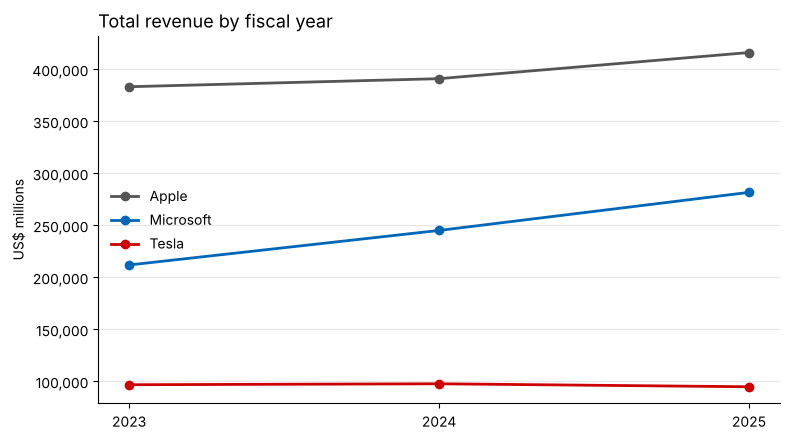

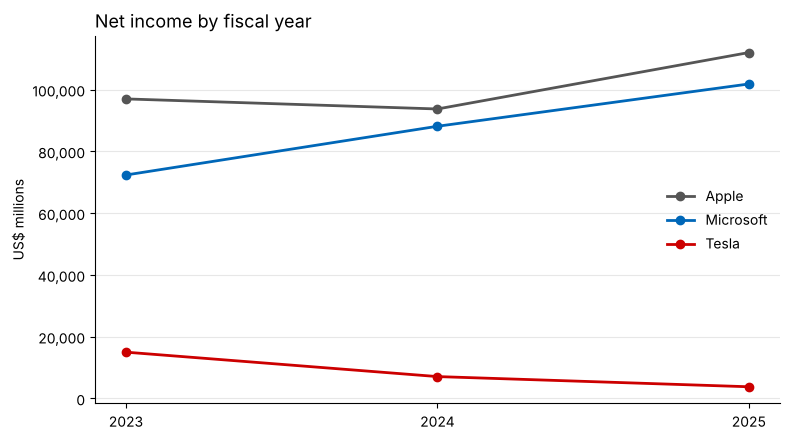

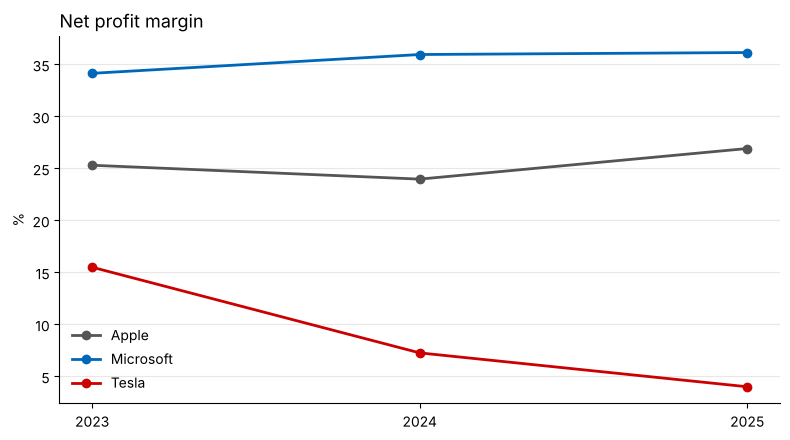

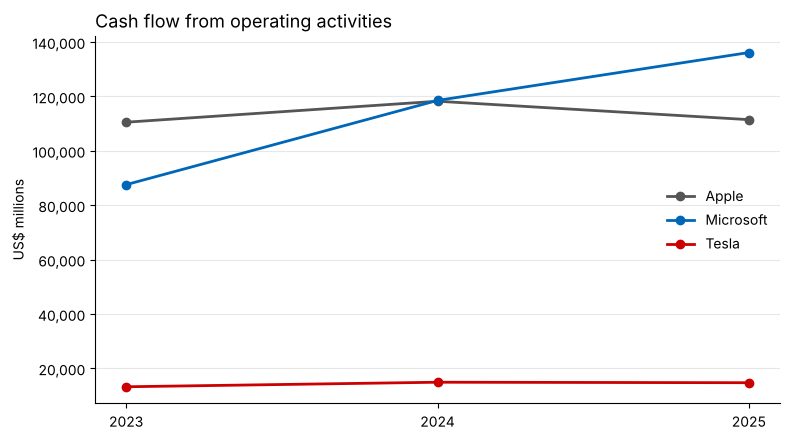

In [11]:
COLOURS = {"Apple": "#555555", "Microsoft": "#0067B8", "Tesla": "#CC0000"}
YEARS = sorted(df['Fiscal Year'].unique())

def plot_metric(column, title, ylabel, filename):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for company, data in df.groupby('Company'):
        ax.plot(data['Fiscal Year'], data[column], marker='o', linewidth=2,
                label=company, color=COLOURS[company])
    ax.set_title(title, fontsize=13, loc='left')
    ax.set_ylabel(ylabel)
    ax.set_xticks(YEARS)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(CHARTS / filename, dpi=150)
    plt.show()

plot_metric('Total Revenue', 'Total revenue by fiscal year', 'US$ millions', 'revenue_trend.png')
plot_metric('Net Income', 'Net income by fiscal year', 'US$ millions', 'net_income_trend.png')
plot_metric('Net Margin (%)', 'Net profit margin', '%', 'net_margin_trend.png')
plot_metric('Cash Flow from Operating Activities', 'Cash flow from operating activities', 'US$ millions', 'operating_cash_flow_trend.png')

## 9. AI-ready preprocessing
The ratios in section 6 are the **feature engineering** step: they turn raw figures into financial health indicators. This section also prepares the data for machine learning and time-series work:
- **Lag features:** each company's prior-year values sit on the same row, so a model or the chatbot can compare years without extra lookups.
- **Encoding:** the company name is categorical, so it is one-hot encoded into numeric 0/1 columns.
- **Time index:** fiscal year stays numeric and rows are ordered by company, then year, which is the standard layout for panel time-series data.
- **Inflation:** figures stay in nominal US dollars, as reported, so they remain traceable to the 10-K. Over three years, inflation does not change any trend or ranking here.
- **Seasonality:** not present in annual data. It becomes relevant once quarterly 10-Q data is added.

In [12]:
ml = df.copy()
LAG_METRICS = ['Total Revenue', 'Net Income', 'Cash Flow from Operating Activities']
for metric in LAG_METRICS:
    ml[f'{metric} (Prior Year)'] = ml.groupby('Company')[metric].shift(1)

company_dummies = pd.get_dummies(ml['Company'], prefix='Company', dtype=int)
ml = pd.concat([ml, company_dummies], axis=1)
ml[['Company', 'Fiscal Year', 'Total Revenue', 'Total Revenue (Prior Year)'] + list(company_dummies.columns)]

,Company,Fiscal Year,Total Revenue,Total Revenue (Prior Year),Company_Apple,Company_Microsoft,Company_Tesla
0,Apple,2023,383285,NaN,1,0,0
1,Apple,2024,391035,"383,285.00",1,0,0
2,Apple,2025,416161,"391,035.00",1,0,0
3,Microsoft,2023,211915,NaN,0,1,0
4,Microsoft,2024,245122,"211,915.00",0,1,0
5,Microsoft,2025,281724,"245,122.00",0,1,0
6,Tesla,2023,96773,NaN,0,0,1
7,Tesla,2024,97690,"96,773.00",0,0,1
8,Tesla,2025,94827,"97,690.00",0,0,1


## 10. Findings and conclusions

### Microsoft: strong and improving
- Revenue grew from **$211.9bn to $281.7bn** (CAGR 15.3%), and net income from **$72.4bn to $101.8bn** (CAGR 18.6%).
- The highest and still-rising net margin, reaching **36.1%** in FY2025.
- Total assets grew 24.3% in FY2024, largely due to the Activision Blizzard acquisition, and a further 20.9% in FY2025. Even so, leverage fell every year, to **44.5%**.
- Operating cash flow rose 55% over the period, to **$136.2bn**.

**Verdict:** the strongest performer on every measure.

### Apple: strong, with growth returning
- The largest revenue base, rising from **$383.3bn to $416.2bn**. Growth accelerated from 2.0% to 6.4%.
- Net income dipped 3.4% in FY2024, mainly because of a one-time income tax charge of about **$10.2bn** linked to the European Commission State Aid decision. It then rose **19.5% to a record $112.0bn** in FY2025.
- Net margin recovered to **26.9%**. Leverage of about 80% reflects Apple's buybacks and dividends, and it fell to 79.5% in FY2025 as equity grew.
- Operating cash flow eased 5.7% to $111.5bn, but remains very large.

**Verdict:** financially very strong, with profit growth back on track.

### Tesla: solid balance sheet, sharply weaker profitability
- Revenue was flat, then fell **2.9% to $94.8bn** in FY2025.
- Net income fell from **$15.0bn to $3.8bn** over two years and the margin dropped from 15.5% to **4.0%**. FY2023 profit was flattered by a one-off tax benefit from releasing a valuation allowance on deferred tax assets. The FY2025 fall reflects lower deliveries and regulatory credit revenue, tariffs, and higher spending on AI and R&D.
- Cash generation held steady at about **$14.7bn** a year, nearly **four times** FY2025 net income, and leverage stayed low at about **40%**.

**Verdict:** the company to watch. The balance sheet and cash flow are sound, but growth has stalled and margins are under pressure.

### Overall
| Measure (FY2023 to FY2025) | Microsoft | Apple | Tesla |
|---|---:|---:|---:|
| Revenue CAGR | **15.3%** | 4.2% | −1.0% |
| Net income CAGR | **18.6%** | 7.5% | −49.7% |
| Average net margin | **35.4%** | 25.4% | 8.9% |
| Latest liabilities to assets | 44.5% | 79.5% | **39.9%** |

### Implications for the GFC chatbot
1. **The data is ready.** It is clean, complete and tidy (one row per company per year), so the chatbot can look up any metric by company and year and compare it with the prior year.
2. **Ratios make the answers fair.** Margin, leverage and cash quality let the chatbot compare a $416bn company with a $95bn one meaningfully.
3. **Context is essential for accuracy.** Tesla's FY2023 tax benefit and Apple's FY2024 tax charge both distort simple year-on-year comparisons. The chatbot should flag one-off items rather than report bare percentages.
4. **Plain-English definitions** (for example, "profit kept from each dollar of sales") meet GFC's requirement that the tool works for clients of any financial expertise.

### Limitations and next steps
- Three years of annual data show direction, but not quarterly movements. Adding **10-Q data** is the natural next step.
- Manual extraction works for three companies. To scale, extraction should be automated through the **SEC EDGAR XBRL API**.
- Segment data (for example cloud, iPhone and energy storage) would let the chatbot explain *why* results changed.

## 11. Export for the chatbot
The analysed dataset is saved as CSV for the chatbot (Task 2), with a machine-learning-ready version and an Excel workbook for business readers.

In [13]:
df.round(2).to_csv(DATA / 'financial_analysis.csv', index=False)
ml.round(2).to_csv(DATA / 'financial_features_ml.csv', index=False)

with pd.ExcelWriter(DATA / 'BCG_GenAI_Task1_Financial_Analysis.xlsx', engine='openpyxl') as writer:
    df[['Company', 'Fiscal Year', 'Fiscal Year End'] + METRICS].to_excel(writer, sheet_name='Raw 10-K Data', index=False)
    df[['Company', 'Fiscal Year'] + GROWTH_COLS].round(2).to_excel(writer, sheet_name='YoY Growth', index=False)
    df[['Company', 'Fiscal Year'] + RATIO_COLS].round(2).to_excel(writer, sheet_name='Ratios', index=False)
    summary.round(2).to_excel(writer, sheet_name='Summary')
    for ws in writer.book.worksheets:
        for col in ws.columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col) + 2
            ws.column_dimensions[col[0].column_letter].width = min(width, 45)
        ws.freeze_panes = 'A2'

print('Saved: financial_analysis.csv, financial_features_ml.csv, BCG_GenAI_Task1_Financial_Analysis.xlsx')

Saved: financial_analysis.csv, financial_features_ml.csv, BCG_GenAI_Task1_Financial_Analysis.xlsx
